# Lab 6: Customer Segmentation and Predictive Analytics Using Machine Learning


---
## 1. Problem Statement
An e-commerce company wants to better understand its customers and improve its marketing decisions. Using historical online retail transaction data, we will:

1. Pre-process transactional data (missing values, cancellations, outliers, scaling) and build customer-level features (RFM, average transaction value, quantity, purchase frequency).
2. Segment customers using **K-Means** (Elbow Method) and compare with **Hierarchical Clustering** (dendrogram); evaluate with **Silhouette Score**.
3. Visualise the segments using **PCA** (2D) and **Plotly** (interactive 3D).
4. Profile each cluster and identify a **high-value segment**.
5. Build **Random Forest** and **SVM** models to predict membership of the high-value segment; compare them using Accuracy, Precision, Recall, F1, ROC-AUC and Confusion Matrix; analyse feature importance.
6. Recommend segment-wise marketing strategies.

## 2. Dataset Description
**UCI Online Retail Dataset** (541,909 rows) - transactions of a UK-based online gift retailer between 01/12/2010 and 09/12/2011.

| Column | Description |
|---|---|
| InvoiceNo | Invoice number (a leading **C** means a cancellation) |
| StockCode | Product code |
| Description | Product name |
| Quantity | Units per transaction |
| InvoiceDate | Date/time of the invoice |
| UnitPrice | Price per unit (GBP) |
| CustomerID | Unique customer identifier |
| Country | Customer's country |

> **R runtime note:** This notebook has been converted to R. In Google Colab, select an R runtime if available, or run it in Jupyter with the R kernel (IRkernel). The first code cell installs required R packages. Hierarchical clustering and exact silhouette calculations can be memory-intensive.\n

## 3. Setup and Data Loading

In [1]:
# Install required packages once if needed
required <- c("readxl", "dplyr", "tidyr", "ggplot2", "cluster", "randomForest", "e1071", "caret", "pROC", "plotly", "scales")
missing <- required[!vapply(required, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing)) install.packages(missing, repos = "https://cloud.r-project.org")

library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(cluster)
library(randomForest)
library(e1071)
library(caret)
library(pROC)
library(plotly)
library(scales)
set.seed(42)
options(warn = 1)


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘lazyeval’, ‘proxy’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘recipes’, ‘reshape2’, ‘crosstalk’



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element


Loading required package

In [2]:
# Download and extract the UCI Online Retail dataset
url <- "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
if (!file.exists("online_retail.zip")) download.file(url, "online_retail.zip", mode = "wb", quiet = TRUE)
if (!file.exists("Online Retail.xlsx")) unzip("online_retail.zip", overwrite = TRUE)

# If download fails, upload Online Retail.xlsx to the notebook working directory.
raw <- read_excel("Online Retail.xlsx")
cat("Shape:", nrow(raw), "rows x", ncol(raw), "columns\n")
head(raw)


Shape: 541909 rows x 8 columns


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom


## 4. Exploratory Data Analysis and Data Quality Check

In [3]:
str(raw)
cat("\nMissing values:\n")
print(colSums(is.na(raw)))
cat(sprintf("\nMissing CustomerID: %.2f%%\n", mean(is.na(raw$CustomerID)) * 100))
cat("Duplicate rows:", sum(duplicated(raw)), "\n")
cat("Cancelled invoices (start with C):", sum(startsWith(as.character(raw$InvoiceNo), "C"), na.rm = TRUE), "\n")
cat("Rows with Quantity <= 0:", sum(raw$Quantity <= 0, na.rm = TRUE), "| Rows with UnitPrice <= 0:", sum(raw$UnitPrice <= 0, na.rm = TRUE), "\n")
summary(raw)


tibble [541,909 × 8] (S3: tbl_df/tbl/data.frame)
 $ InvoiceNo  : chr [1:541909] "536365" "536365" "536365" "536365" ...
 $ StockCode  : chr [1:541909] "85123A" "71053" "84406B" "84029G" ...
 $ Description: chr [1:541909] "WHITE HANGING HEART T-LIGHT HOLDER" "WHITE METAL LANTERN" "CREAM CUPID HEARTS COAT HANGER" "KNITTED UNION FLAG HOT WATER BOTTLE" ...
 $ Quantity   : num [1:541909] 6 6 8 6 6 2 6 6 6 32 ...
 $ InvoiceDate: POSIXct[1:541909], format: "2010-12-01 08:26:00" "2010-12-01 08:26:00" ...
 $ UnitPrice  : num [1:541909] 2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69 ...
 $ CustomerID : num [1:541909] 17850 17850 17850 17850 17850 ...
 $ Country    : chr [1:541909] "United Kingdom" "United Kingdom" "United Kingdom" "United Kingdom" ...

Missing values:
  InvoiceNo   StockCode Description    Quantity InvoiceDate   UnitPrice 
          0           0        1454           0           0           0 
 CustomerID     Country 
     135080           0 

Missing CustomerID: 24.93%
Dupl

     InvoiceNo          StockCode         Description        Quantity         
 Length   :541909   Length   :541909   Length   :541909   Min.   :-80995.000  
 N.unique : 25900   N.unique :  4070   N.unique :  4211   1st Qu.:     1.000  
 N.blank  :     0   N.blank  :     0   N.blank  :     0   Median :     3.000  
 Min.nchar:     6   Min.nchar:     1   Min.nchar:     1   Mean   :     9.552  
 Max.nchar:     7   Max.nchar:    12   Max.nchar:    35   3rd Qu.:    10.000  
                                       NAs      :  1454   Max.   : 80995.000  
                                                                              
  InvoiceDate                    UnitPrice            CustomerID    
 Min.   :2010-12-01 08:26:00   Min.   :-11062.060   Min.   :12346   
 1st Qu.:2011-03-28 11:34:00   1st Qu.:     1.250   1st Qu.:13953   
 Median :2011-07-19 17:17:00   Median :     2.080   Median :15152   
 Mean   :2011-07-04 13:34:57   Mean   :     4.611   Mean   :15288   
 3rd Qu.:2011-10-19 11:

## 5. Data Preprocessing

| Issue | Treatment |
|---|---|
| Missing `CustomerID` (~25%) | Dropped - segmentation needs a customer identity |
| Cancellations (`InvoiceNo` starts with C) | Counted per customer (used as a feature `CancelRate`), then removed from sales data |
| Negative / zero quantity or price | Removed (returns, adjustments, free samples) |
| Non-product stock codes (POST, DOT, M, BANK CHARGES ...) | Removed |
| Duplicate rows | Removed |

In [4]:
df <- raw
# Keep invoice numbers as character values so leading C cancellation markers are preserved.
df$InvoiceNo <- as.character(df$InvoiceNo)
df$StockCode <- as.character(df$StockCode)
df$IsCancel <- startsWith(df$InvoiceNo, "C")

# Count distinct cancelled invoices per known customer before removing cancellations.
cancel_counts <- df %>%
  filter(IsCancel, !is.na(CustomerID)) %>%
  mutate(CustomerID = as.character(as.integer(CustomerID))) %>%
  group_by(CustomerID) %>%
  summarise(CancelCount = n_distinct(InvoiceNo), .groups = "drop")

# Apply the same cleaning rules described in the original notebook.
df <- df %>%
  filter(!is.na(CustomerID)) %>%
  mutate(CustomerID = as.character(as.integer(CustomerID))) %>%
  filter(!IsCancel, Quantity > 0, UnitPrice > 0)
non_product <- c("POST", "D", "M", "BANK CHARGES", "PADS", "DOT", "CRUK", "C2", "S", "AMAZONFEE", "B")
df <- df %>%
  filter(!toupper(StockCode) %in% non_product) %>%
  distinct() %>%
  mutate(InvoiceDate = as.POSIXct(InvoiceDate, tz = "UTC"), TotalPrice = Quantity * UnitPrice)
cat("Clean transactions:", nrow(df), "| Customers:", n_distinct(df$CustomerID), "\n")
cat("Date range:", as.character(min(df$InvoiceDate)), "->", as.character(max(df$InvoiceDate)), "\n")


Clean transactions: 391150 | Customers: 4334 
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00 


## 6. Customer-Level Feature Engineering

| Feature | Definition |
|---|---|
| **Recency** | Days since last purchase (snapshot = last date + 1 day) |
| **Frequency** | Number of unique invoices |
| **Monetary** | Total spend |
| AvgTransactionValue | Monetary / Frequency (mean invoice value) |
| TotalQuantity | Total units purchased |
| AvgQtyPerInvoice | Mean units per invoice |
| UniqueProducts | Number of distinct products bought |
| AvgUnitPrice | Mean unit price of items bought |
| TenureDays | Days between first and last purchase |
| PurchaseFrequency | Invoices per month of active tenure |
| CancelRate | Cancelled invoices / (valid + cancelled invoices) |
| IsUK | 1 if the customer's main country is the UK |

In [5]:
snapshot <- max(df$InvoiceDate, na.rm = TRUE) + 86400  # one day in POSIXct seconds

inv <- df %>%
  group_by(CustomerID, InvoiceNo) %>%
  summarise(InvoiceValue = sum(TotalPrice), InvoiceQty = sum(Quantity), .groups = "drop")

# Most common country per customer. Ties are resolved alphabetically for reproducibility.
mode_country <- function(x) {
  tab <- sort(table(x), decreasing = TRUE)
  names(tab)[1]
}

cust <- df %>%
  group_by(CustomerID) %>%
  summarise(
    Monetary = sum(TotalPrice),
    TotalQuantity = sum(Quantity),
    UniqueProducts = n_distinct(StockCode),
    AvgUnitPrice = mean(UnitPrice),
    FirstPurchase = min(InvoiceDate),
    LastPurchase = max(InvoiceDate),
    Country = mode_country(Country),
    .groups = "drop"
  ) %>%
  left_join(inv %>% group_by(CustomerID) %>% summarise(
    Frequency = n_distinct(InvoiceNo),
    AvgTransactionValue = mean(InvoiceValue),
    AvgQtyPerInvoice = mean(InvoiceQty), .groups = "drop"), by = "CustomerID") %>%
  left_join(cancel_counts, by = "CustomerID") %>%
  mutate(
    CancelCount = replace_na(CancelCount, 0),
    Recency = as.numeric(snapshot - LastPurchase),
    TenureDays = as.numeric(LastPurchase - FirstPurchase),
    PurchaseFrequency = Frequency / (TenureDays / 30 + 1),
    CancelRate = CancelCount / (Frequency + CancelCount),
    IsUK = as.integer(Country == "United Kingdom")
  ) %>%
  select(-FirstPurchase, -LastPurchase)

cat("Customer table:", nrow(cust), "rows x", ncol(cust), "columns\n")
cat("Missing values in numeric/customer features:", sum(is.na(select(cust, where(is.numeric)))), "\n")
head(cust)


Customer table: 4334 rows x 15 columns
Missing values in numeric/customer features: 0 


CustomerID,Monetary,TotalQuantity,UniqueProducts,AvgUnitPrice,Country,Frequency,AvgTransactionValue,AvgQtyPerInvoice,CancelCount,Recency,TenureDays,PurchaseFrequency,CancelRate,IsUK
<chr>,<dbl>,<dbl>,<int>,<dbl>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
12346,77183.60,74215,1,1.040000,United Kingdom,1,77183.6000,74215.00000,1,326.117361,0,1.000000e+00,0.5,1
12347,4310.00,2458,103,2.644011,Iceland,7,615.7143,351.14286,0,2.873611,31539300,6.658353e-06,0.0,0
12348,1437.24,2332,21,0.692963,Finland,4,359.3100,583.00000,0,75.984028,24429840,4.912020e-06,0.0,0
12349,1457.55,630,72,4.237500,Italy,1,1457.5500,630.00000,0,19.124306,0,1.000000e+00,0.0,0
12350,294.40,196,16,1.581250,Norway,1,294.4000,196.00000,0,310.867361,0,1.000000e+00,0.0,0
12352,1385.74,526,57,4.075455,Norway,7,197.9629,75.14286,3,36.925694,22471440,9.345183e-06,0.3,0


In [6]:
summary(cust)


     CustomerID      Monetary         TotalQuantity      UniqueProducts   
 Length   :4334   Min.   :     3.75   Min.   :     1.0   Min.   :   1.00  
 N.unique :4334   1st Qu.:   304.24   1st Qu.:   159.2   1st Qu.:  16.00  
 N.blank  :   0   Median :   662.57   Median :   377.5   Median :  35.00  
 Min.nchar:   5   Mean   :  2015.97   Mean   :  1186.4   Mean   :  61.43  
 Max.nchar:   5   3rd Qu.:  1631.62   3rd Qu.:   989.8   3rd Qu.:  77.00  
                  Max.   :279138.02   Max.   :196844.0   Max.   :1785.00  
  AvgUnitPrice           Country       Frequency       AvgTransactionValue
 Min.   :  0.1225   Length   :4334   Min.   :  1.000   Min.   :    3.75   
 1st Qu.:  2.1548   N.unique :  37   1st Qu.:  1.000   1st Qu.:  177.20   
 Median :  2.8275   N.blank  :   0   Median :  2.000   Median :  289.56   
 Mean   :  3.4518   Min.nchar:   3   Mean   :  4.246   Mean   :  415.48   
 3rd Qu.:  3.6892   Max.nchar:  20   3rd Qu.:  5.000   3rd Qu.:  423.41   
 Max.   :434.6500        

## 7. Outlier Handling and Feature Scaling
RFM variables are heavily right-skewed with extreme outliers (a few wholesale buyers). We:
1. **Winsorise** (cap) numeric features at the 1st/99th percentile,
2. apply **log(1 + x)** to reduce skew,
3. apply **StandardScaler** (mean 0, std 1) because K-Means/Hierarchical/SVM are distance based.

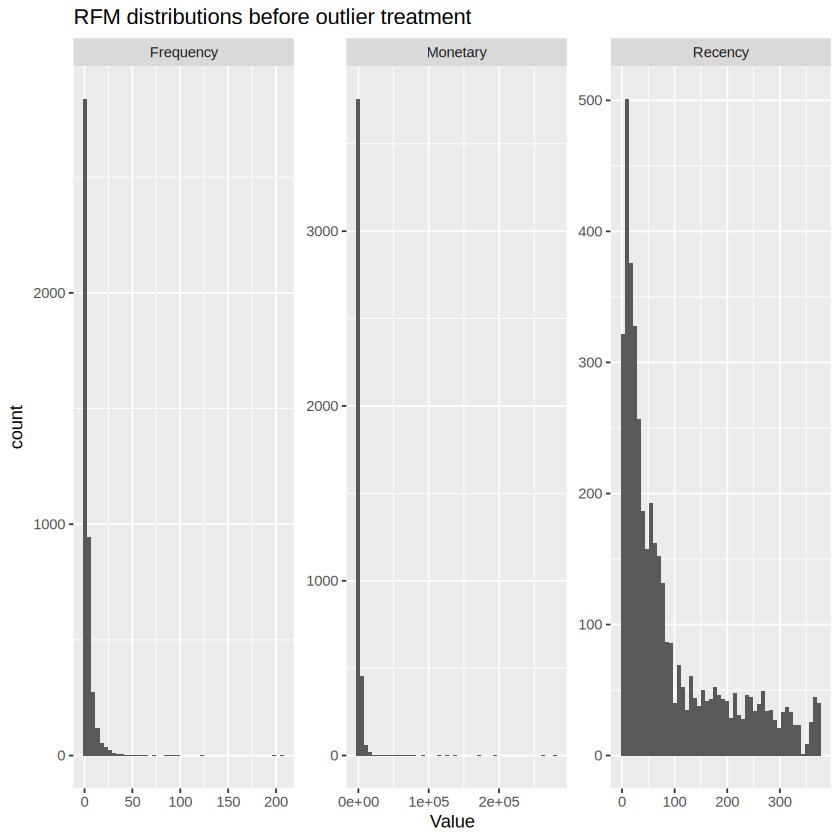

Scaled clustering matrix: 4334 rows x 3 columns


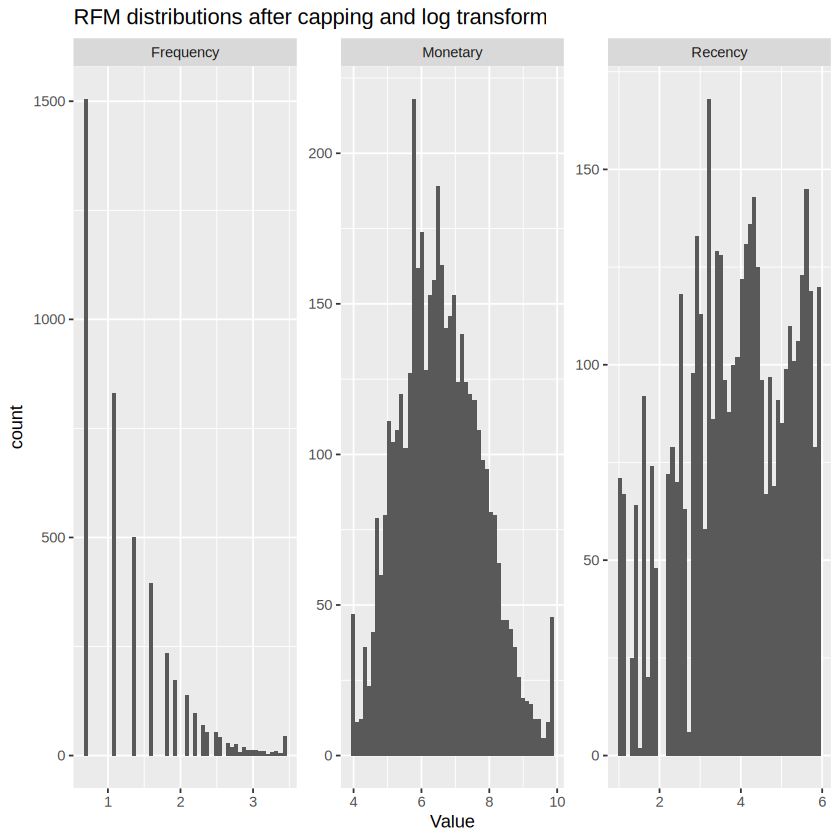

In [7]:
num_cols <- c("Recency", "Frequency", "Monetary", "AvgTransactionValue", "TotalQuantity", "AvgQtyPerInvoice",
              "UniqueProducts", "AvgUnitPrice", "TenureDays", "PurchaseFrequency", "CancelRate")

# Before: distributions of the three RFM variables
cust_long <- cust %>% select(all_of(c("Recency", "Frequency", "Monetary"))) %>%
  pivot_longer(everything(), names_to = "Feature", values_to = "Value")
ggplot(cust_long, aes(Value)) + geom_histogram(bins = 50) + facet_wrap(~Feature, scales = "free") +
  labs(title = "RFM distributions before outlier treatment")

# Winsorise numeric features at the 1st and 99th percentiles.
cust_cap <- cust
for (col in num_cols) {
  bounds <- quantile(cust[[col]], c(0.01, 0.99), na.rm = TRUE, names = FALSE)
  cust_cap[[col]] <- pmin(pmax(cust[[col]], bounds[1]), bounds[2])
}

# Log transform. These features are non-negative after the cleaning steps.
cust_log <- cust_cap
cust_log[num_cols] <- lapply(cust_cap[num_cols], log1p)

cust_log_long <- cust_log %>% select(all_of(c("Recency", "Frequency", "Monetary"))) %>%
  pivot_longer(everything(), names_to = "Feature", values_to = "Value")
ggplot(cust_log_long, aes(Value)) + geom_histogram(bins = 50) + facet_wrap(~Feature, scales = "free") +
  labs(title = "RFM distributions after capping and log transform")

# Standardise RFM features (mean 0, standard deviation 1).
rfm_cols <- c("Recency", "Frequency", "Monetary")
X <- scale(as.matrix(cust_log[, rfm_cols]))
cat("Scaled clustering matrix:", nrow(X), "rows x", ncol(X), "columns\n")


## 8. K-Means Clustering - Elbow Method and Silhouette
We cluster on the scaled **R, F, M** features. The remaining behavioural features (avg. transaction value, quantity, purchase frequency, ...) are used later to **profile** the clusters and to **predict** the high-value segment (this avoids target leakage, since the segment is defined by RFM).

   k  Inertia Silhouette
1  2 6304.011  0.4361196
2  3 4692.094  0.3371122
3  4 3742.878  0.3360507
4  5 3110.186  0.3190706
5  6 2675.327  0.3141543
6  7 2387.961  0.3128836
7  8 2184.583  0.3004121
8  9 2015.608  0.2843770
9 10 1864.752  0.2863873


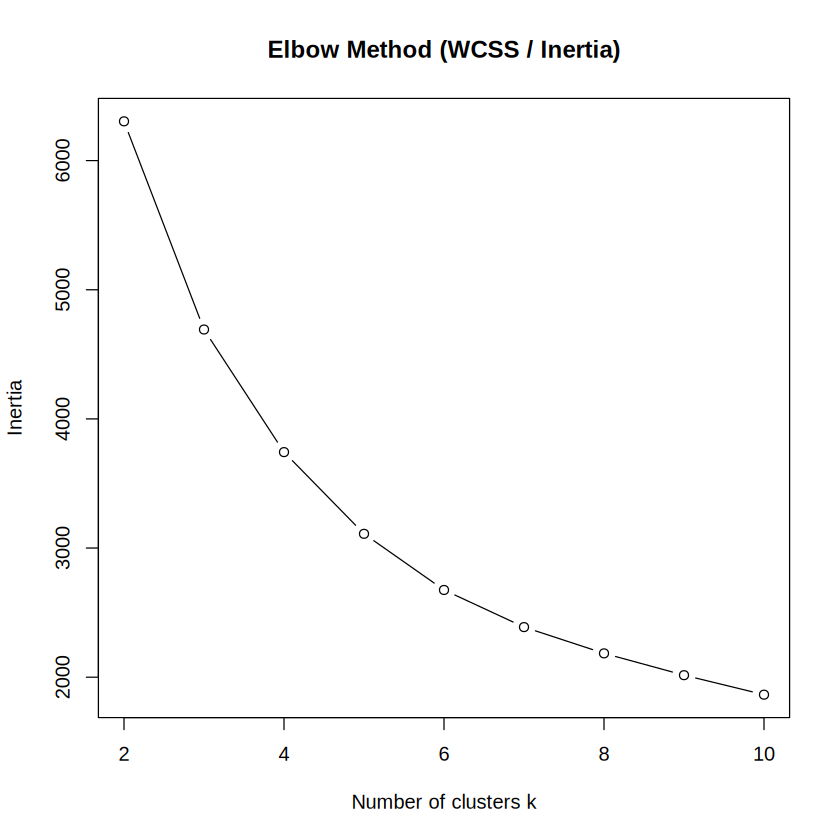

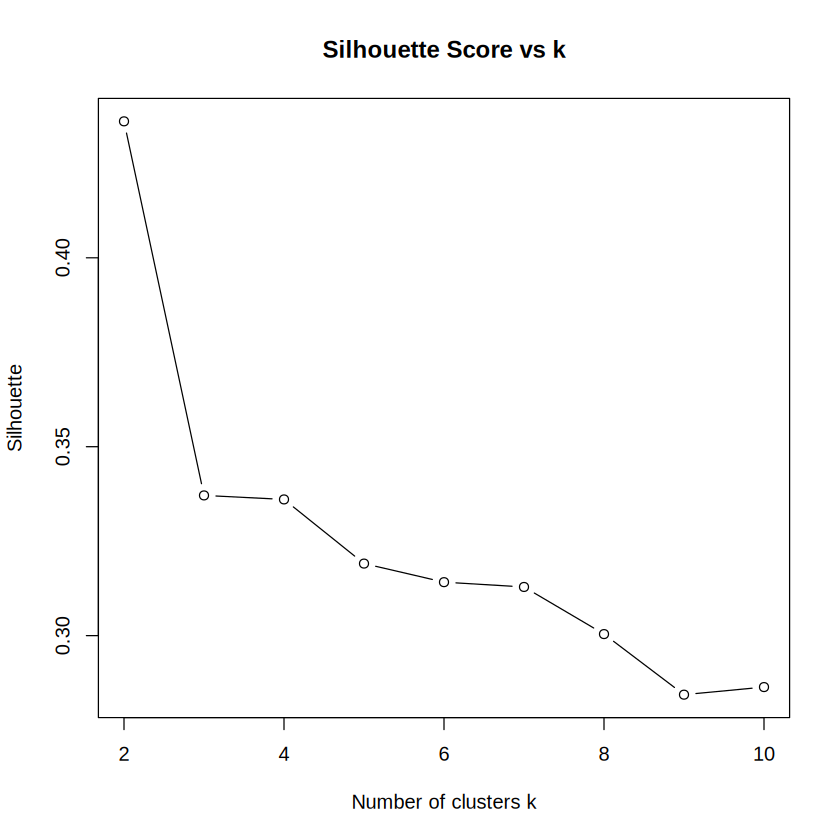

In [8]:
K_RANGE <- 2:10
inertia <- numeric(length(K_RANGE))
sil <- numeric(length(K_RANGE))
for (i in seq_along(K_RANGE)) {
  k <- K_RANGE[i]
  km <- kmeans(X, centers = k, nstart = 10, iter.max = 100)
  inertia[i] <- km$tot.withinss
  # Exact silhouette calculation is O(n^2); sample up to 2,000 customers for speed on larger datasets.
  sample_idx <- if (nrow(X) > 2000) sample(seq_len(nrow(X)), 2000) else seq_len(nrow(X))
  sil[i] <- mean(cluster::silhouette(km$cluster[sample_idx], dist(X[sample_idx, , drop = FALSE]))[, "sil_width"])
}
metrics_k <- data.frame(k = K_RANGE, Inertia = inertia, Silhouette = sil)
print(metrics_k)
plot(metrics_k$k, metrics_k$Inertia, type = "b", xlab = "Number of clusters k", ylab = "Inertia", main = "Elbow Method (WCSS / Inertia)")
plot(metrics_k$k, metrics_k$Silhouette, type = "b", xlab = "Number of clusters k", ylab = "Silhouette", main = "Silhouette Score vs k")


In [9]:
# Choose the best silhouette among k >= 3; override K manually if the elbow plot suggests otherwise.
K <- metrics_k$k[which.max(metrics_k$Silhouette[metrics_k$k >= 3]) + 2]
cat("Chosen number of clusters K =", K, "\n")
kmeans_fit <- kmeans(X, centers = K, nstart = 20, iter.max = 100)
cust$KMeans_Cluster <- factor(kmeans_fit$cluster - 1L)
sample_idx <- if (nrow(X) > 2000) sample(seq_len(nrow(X)), 2000) else seq_len(nrow(X))
sil_km <- mean(cluster::silhouette(kmeans_fit$cluster[sample_idx], dist(X[sample_idx, , drop = FALSE]))[, "sil_width"])
cat(sprintf("K-Means Silhouette Score (sampled if >2,000 customers): %.4f\n", sil_km))
print(table(cust$KMeans_Cluster))


Chosen number of clusters K = 4 
K-Means Silhouette Score (sampled if >2,000 customers): 0.3413

   0    1    2    3 
 753  888 1515 1178 


## 9. Hierarchical Clustering and Dendrogram

               Method Clusters Silhouette Score
1             K-Means        4        0.3413419
2 Hierarchical (Ward)        4        0.2724854
Adjusted Rand Index between the two segmentations: 0.4188 (1 = identical)
      Hierarchical
KMeans    0    1    2    3
     0  229  524    0    0
     1  250    0   76  562
     2    0    0 1212  303
     3  788    5  384    1


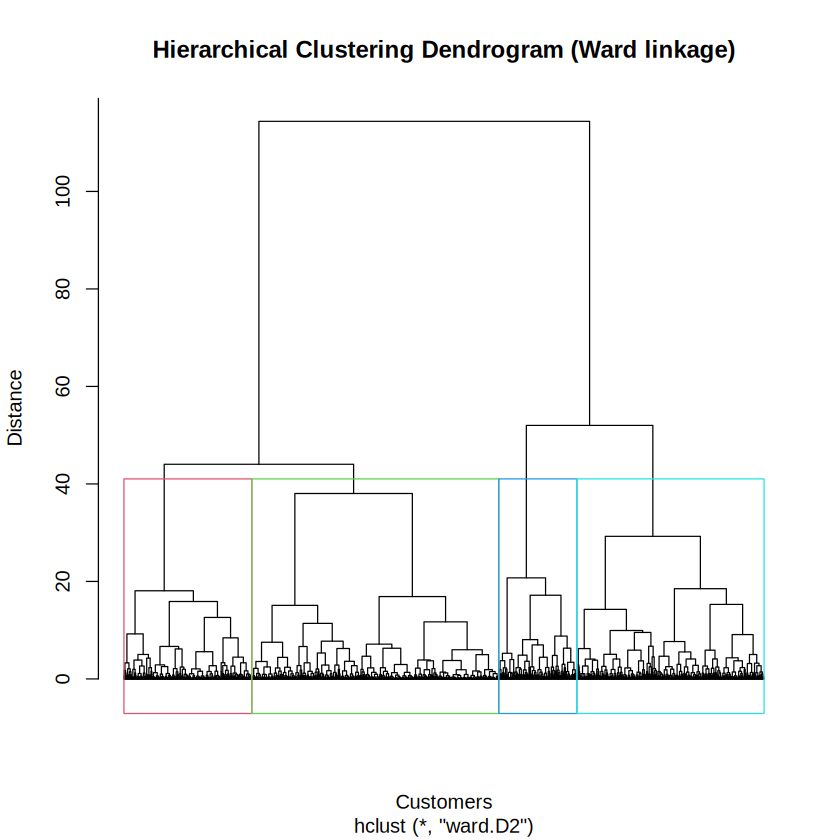

In [10]:
# Ward hierarchical clustering can be memory-intensive because it uses pairwise distances.
# The full customer dataset is used here, matching the original analysis.
D <- dist(X)
hc <- hclust(D, method = "ward.D2")
plot(hc, labels = FALSE, hang = -1, main = "Hierarchical Clustering Dendrogram (Ward linkage)", xlab = "Customers", ylab = "Distance")
rect.hclust(hc, k = K, border = 2:(K + 1))
agg_cluster <- cutree(hc, k = K)
cust$Hier_Cluster <- factor(agg_cluster - 1L)
sil_hc <- mean(cluster::silhouette(agg_cluster[sample_idx], dist(X[sample_idx, , drop = FALSE]))[, "sil_width"])
ari_fun <- function(a, b) {
  tab <- table(a, b); n <- sum(tab)
  choose2 <- function(z) z * (z - 1) / 2
  sum_ij <- sum(choose2(tab)); sum_a <- sum(choose2(rowSums(tab))); sum_b <- sum(choose2(colSums(tab)))
  total <- choose2(n); expected <- sum_a * sum_b / total; maximum <- (sum_a + sum_b) / 2
  if (maximum == expected) return(1)
  (sum_ij - expected) / (maximum - expected)
}
ari <- ari_fun(cust$KMeans_Cluster, cust$Hier_Cluster)
comparison <- data.frame(Method = c("K-Means", "Hierarchical (Ward)"), Clusters = c(K, K),
                         `Silhouette Score` = c(sil_km, sil_hc), check.names = FALSE)
print(comparison)
cat(sprintf("Adjusted Rand Index between the two segmentations: %.4f (1 = identical)\n", ari))
print(table(KMeans = cust$KMeans_Cluster, Hierarchical = cust$Hier_Cluster))


**Interpretation:** the higher Silhouette Score indicates better-separated, more compact clusters. The Adjusted Rand Index and the cross-tab show how strongly the two methods agree. K-Means is chosen as the final segmentation because it is scalable and gives stable centroids (change this if your results say otherwise).

## 10. PCA - 2D Visualisation of Segments

Explained variance ratio: 0.7536 0.1865 | total = 94.01% 
             PC1   PC2
Recency   -0.512 0.850
Frequency  0.618 0.264
Monetary   0.597 0.456


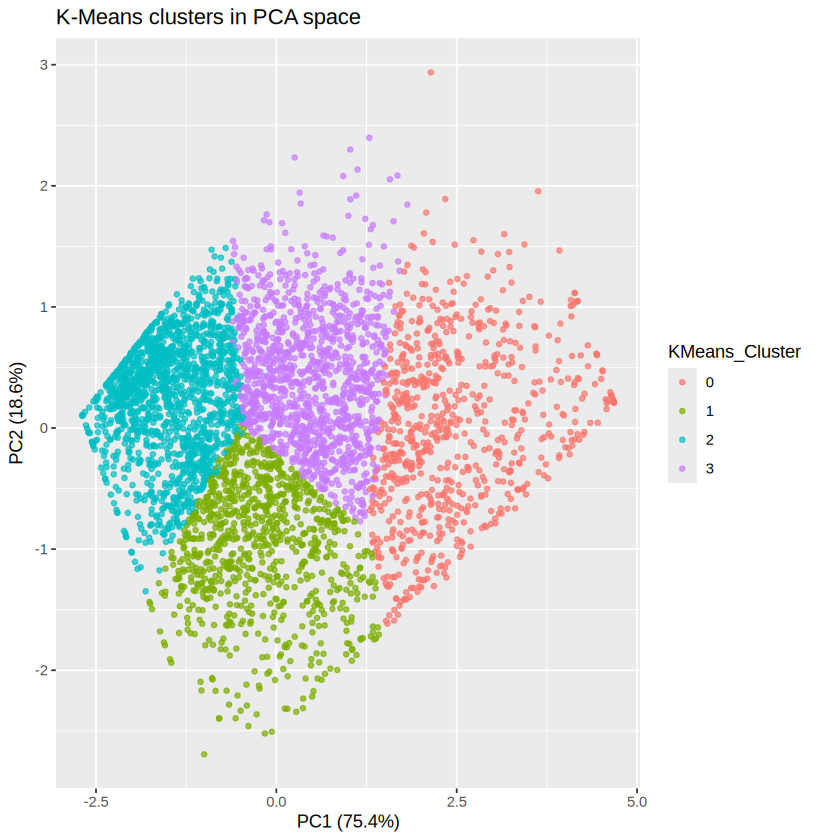

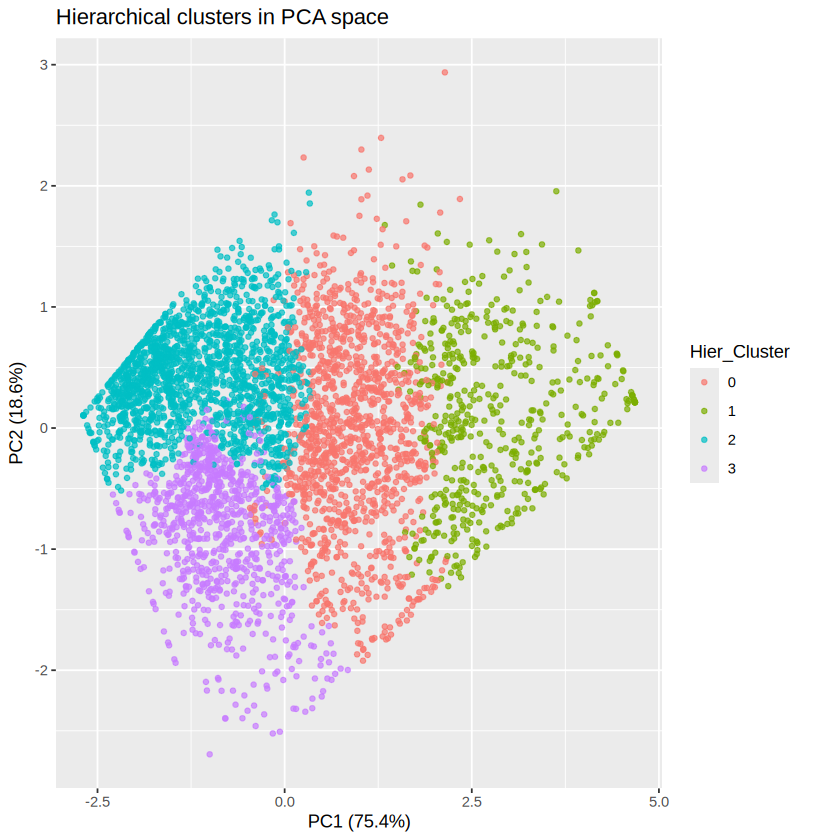

In [11]:
pca <- prcomp(X, center = FALSE, scale. = FALSE)
X_pca <- pca$x[, 1:2, drop = FALSE]
variance <- (pca$sdev^2) / sum(pca$sdev^2)
cat("Explained variance ratio:", round(variance[1:2], 4), "| total =", percent(sum(variance[1:2]), accuracy = 0.01), "\n")
print(round(pca$rotation[, 1:2, drop = FALSE], 3))
pca_df <- data.frame(PC1 = X_pca[, 1], PC2 = X_pca[, 2],
                     KMeans_Cluster = cust$KMeans_Cluster, Hier_Cluster = cust$Hier_Cluster)
g1 <- ggplot(pca_df, aes(PC1, PC2, colour = KMeans_Cluster)) + geom_point(alpha = 0.7, size = 1.2) +
  labs(title = "K-Means clusters in PCA space", x = sprintf("PC1 (%.1f%%)", variance[1] * 100), y = sprintf("PC2 (%.1f%%)", variance[2] * 100))
g2 <- ggplot(pca_df, aes(PC1, PC2, colour = Hier_Cluster)) + geom_point(alpha = 0.7, size = 1.2) +
  labs(title = "Hierarchical clusters in PCA space", x = sprintf("PC1 (%.1f%%)", variance[1] * 100), y = sprintf("PC2 (%.1f%%)", variance[2] * 100))
print(g1); print(g2)


## 11. Cluster-wise Customer Profiling

# A tibble: 4 × 14
  KMeans_Cluster Customers `% Customers` `Revenue Share %` Recency Frequency
  <fct>              <dbl>         <dbl>             <dbl>   <dbl>     <dbl>
1 0                    753          17.4             65.7     12.6     13.2 
2 1                    888          20.5              4.8     22.6      1.92
3 2                   1515          35.0              5.99   193.       1.31
4 3                   1178          27.2             23.5     69.7      4.04
# ℹ 8 more variables: Monetary <dbl>, AvgTransactionValue <dbl>,
#   TotalQuantity <dbl>, AvgQtyPerInvoice <dbl>, UniqueProducts <dbl>,
#   PurchaseFrequency <dbl>, TenureDays <dbl>, CancelRate <dbl>
                            0                             1 
     "Champions (High-Value)" "Loyal / Potential Loyalists" 
                            2                             3 
            "Lost / Inactive"       "At-Risk / Hibernating" 


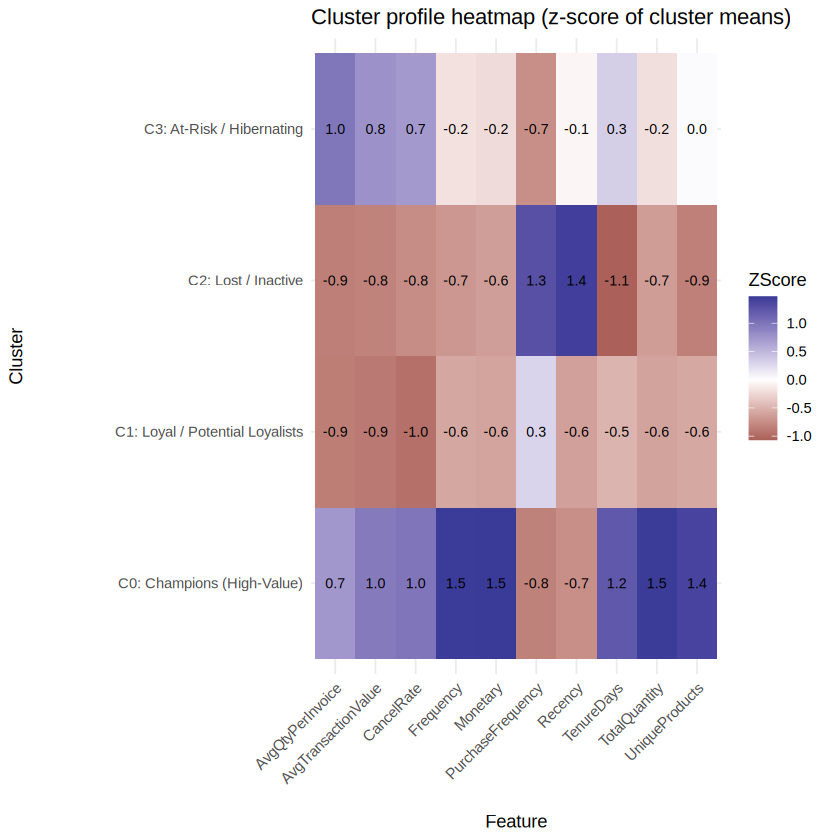

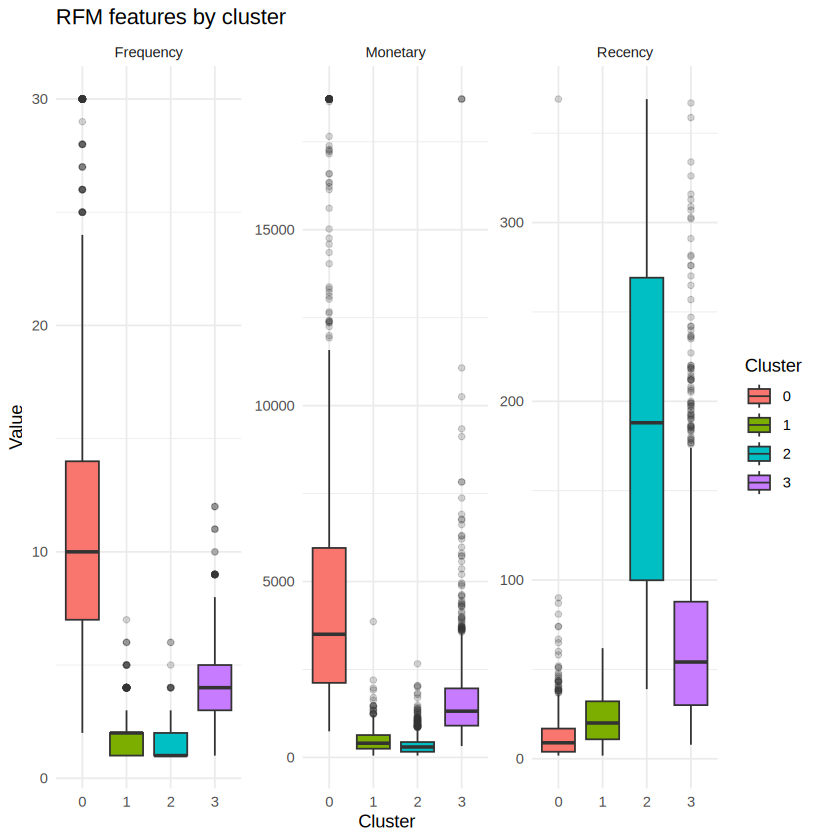

In [12]:
profile_cols <- c("Recency", "Frequency", "Monetary", "AvgTransactionValue", "TotalQuantity", "AvgQtyPerInvoice",
                  "UniqueProducts", "PurchaseFrequency", "TenureDays", "CancelRate")
profile <- cust %>% group_by(KMeans_Cluster) %>%
  summarise(Customers = n(), across(all_of(profile_cols), mean), .groups = "drop") %>%
  mutate(`% Customers` = Customers / sum(Customers) * 100) %>%
  left_join(cust %>% group_by(KMeans_Cluster) %>% summarise(`Revenue Share %` = sum(Monetary) / sum(cust$Monetary) * 100, .groups = "drop"), by = "KMeans_Cluster")
print(profile %>% select(KMeans_Cluster, Customers, `% Customers`, `Revenue Share %`, all_of(profile_cols)) %>% mutate(across(where(is.numeric), ~round(.x, 2))))

# Name clusters by average Monetary value and Recency, as in the original notebook.
ordered_clusters <- as.character(profile$KMeans_Cluster[order(profile$Monetary, decreasing = TRUE)])
med_rec <- median(profile$Recency)
seg_names <- setNames(rep("", nrow(profile)), as.character(profile$KMeans_Cluster))
for (i in seq_along(ordered_clusters)) {
  cl <- ordered_clusters[i]
  row <- profile[as.character(profile$KMeans_Cluster) == cl, ]
  if (i == 1) seg_names[cl] <- "Champions (High-Value)"
  else if (i == length(ordered_clusters)) seg_names[cl] <- if (row$Recency >= med_rec) "Lost / Inactive" else "New / Low-Value"
  else seg_names[cl] <- if (row$Recency < med_rec) "Loyal / Potential Loyalists" else "At-Risk / Hibernating"
}
# Make repeated labels unique.
seg_label_values <- make.unique(unname(seg_names), sep = " #")
names(seg_label_values) <- names(seg_names)
seg_names <- seg_label_values
cust$Segment <- unname(seg_names[as.character(cust$KMeans_Cluster)])
print(seg_names)

# Heatmap of z-scored cluster means
hm <- as.data.frame(scale(as.matrix(profile[, profile_cols])))
hm$Cluster <- paste0("C", profile$KMeans_Cluster, ": ", seg_names[as.character(profile$KMeans_Cluster)])
hm_long <- hm %>% pivot_longer(all_of(profile_cols), names_to = "Feature", values_to = "ZScore")
print(ggplot(hm_long, aes(Feature, Cluster, fill = ZScore)) + geom_tile() + geom_text(aes(label = sprintf("%.1f", ZScore)), size = 3) +
        scale_fill_gradient2() + theme_minimal() + theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
        labs(title = "Cluster profile heatmap (z-score of cluster means)"))
box_long <- cust_cap %>% mutate(Cluster = cust$KMeans_Cluster) %>% select(Cluster, Recency, Frequency, Monetary) %>%
  pivot_longer(c(Recency, Frequency, Monetary), names_to = "Feature", values_to = "Value")
print(ggplot(box_long, aes(Cluster, Value, fill = Cluster)) + geom_boxplot(outlier.alpha = 0.2) + facet_wrap(~Feature, scales = "free_y") +
        labs(title = "RFM features by cluster") + theme_minimal())


## 12. Defining the High-Value Customer Segment
The cluster with the **highest average Monetary value** (typically also high Frequency and low Recency) is treated as the **High-Value** segment. The target is `1` if the customer belongs to it, else `0`.

In [13]:
hv_cluster <- as.character(profile$KMeans_Cluster[which.max(profile$Monetary)])
cat("High-value cluster =", hv_cluster, "(", seg_names[hv_cluster], ")\n")
cust$HighValue <- as.integer(as.character(cust$KMeans_Cluster) == hv_cluster)
print(table(cust$HighValue))
cat(sprintf("Class balance: %.1f%% high-value\n", mean(cust$HighValue) * 100))
cat(sprintf("Revenue share of high-value customers: %.1f%%\n", sum(cust$Monetary[cust$HighValue == 1]) / sum(cust$Monetary) * 100))


High-value cluster = 0 ( Champions (High-Value) )

   0    1 
3581  753 
Class balance: 17.4% high-value
Revenue share of high-value customers: 65.7%


## 13. Supervised Learning - Predicting High-Value Customers

**Avoiding data leakage:** the segment was *created* from Recency, Frequency and Monetary. Using them as inputs would make the task trivial. Therefore the classifiers use only the **other behavioural features** (avg. transaction value, quantity, product variety, purchase frequency, tenure, cancellation rate, country), which are not used by the clustering algorithm.

Models: **Random Forest** and **SVM (RBF)**, tuned with 5-fold stratified `GridSearchCV` (scoring = F1), with `class_weight="balanced"` to handle class imbalance.

In [16]:
if (!requireNamespace("MLmetrics", quietly = TRUE)) install.packages("MLmetrics", repos = "https://cloud.r-project.org")
if (!requireNamespace("kernlab", quietly = TRUE)) install.packages("kernlab", repos = "https://cloud.r-project.org")

feat_cols <- c("AvgTransactionValue", "TotalQuantity", "AvgQtyPerInvoice", "UniqueProducts", "AvgUnitPrice",
               "TenureDays", "PurchaseFrequency", "CancelRate", "IsUK")
Xs <- cust_cap[, feat_cols, drop = FALSE]
y <- factor(ifelse(cust$HighValue == 1, "HighValue", "NotHighValue"), levels = c("NotHighValue", "HighValue"))
set.seed(42)
train_idx <- createDataPartition(y, p = 0.75, list = FALSE)
X_train <- Xs[train_idx, , drop = FALSE]; X_test <- Xs[-train_idx, , drop = FALSE]
y_train <- y[train_idx]; y_test <- y[-train_idx]
cat("Train:", nrow(X_train), "rows; Test:", nrow(X_test), "rows\n")

# Random Forest grid search using stratified 5-fold CV and F1 as the selection metric.
ctrl <- trainControl(method = "cv", number = 5, classProbs = TRUE,
                     summaryFunction = prSummary, savePredictions = "final")
rf_grid <- expand.grid(mtry = unique(pmin(c(2, 4, 6), ncol(X_train))))
set.seed(42)
rf_fit <- train(x = X_train, y = y_train, method = "rf", metric = "F", trControl = ctrl,
                tuneGrid = rf_grid, ntree = 300, importance = TRUE, classwt = c(1, sum(y_train == "NotHighValue") / sum(y_train == "HighValue")))
rf <- rf_fit$finalModel
cat("RF best mtry:", rf_fit$bestTune$mtry, "| CV F-measure:", max(rf_fit$results$F, na.rm = TRUE), "\n")

# SVM with log1p + scaling. caret tunes cost and sigma using stratified CV.
svm_train <- as.data.frame(lapply(X_train, log1p))
svm_test <- as.data.frame(lapply(X_test, log1p))
pp <- preProcess(svm_train, method = c("center", "scale"))
svm_train_scaled <- predict(pp, svm_train); svm_test_scaled <- predict(pp, svm_test)
svm_grid <- expand.grid(sigma = c(0.05, 0.1, 0.5), C = c(0.5, 1, 5, 10))
set.seed(42)
svm_fit <- train(x = svm_train_scaled, y = y_train, method = "svmRadial", metric = "F",
                 trControl = ctrl, tuneGrid = svm_grid, class.weights = c(NotHighValue = 1, HighValue = sum(y_train == "NotHighValue") / sum(y_train == "HighValue")))
cat("SVM best parameters:\n"); print(svm_fit$bestTune)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Train: 3251 rows; Test: 1083 rows


Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Setting row names on a

RF best mtry: 4 | CV F-measure: 0.9647022 
SVM best parameters:
  sigma   C
1  0.05 0.5


## 14. Model Evaluation and Comparison

          Model Accuracy Precision Recall F1-Score ROC-AUC
1 Random Forest   0.9409    0.8735 0.7713   0.8192  0.9831
2     SVM (RBF)   0.1477    0.0014 0.0053   0.0022  0.0186


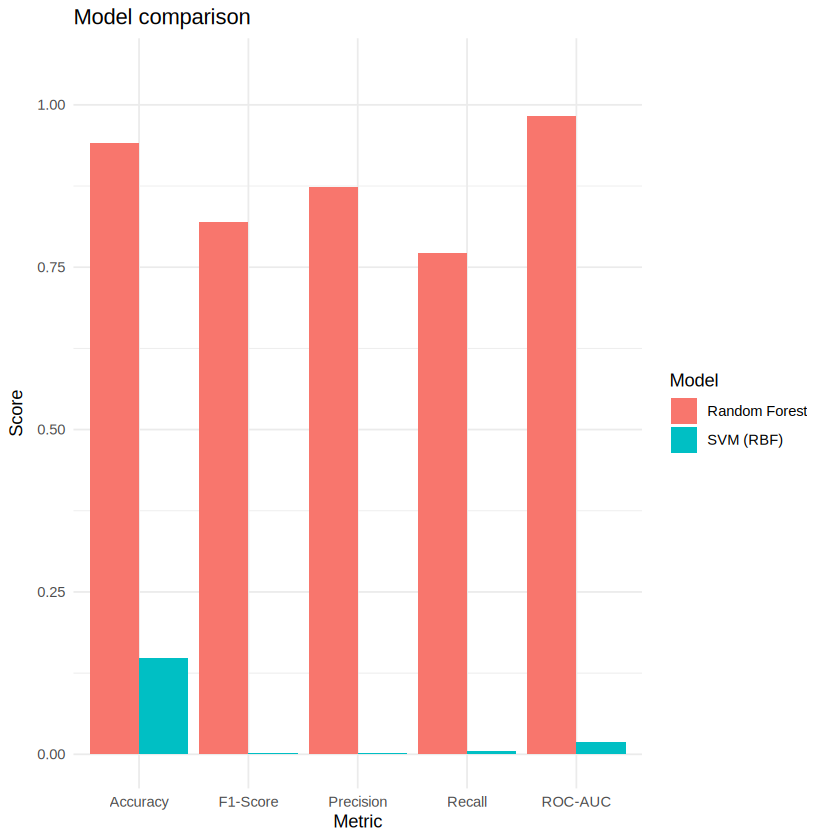

In [17]:
# Predict labels and probabilities for both models.
rf_pred <- predict(rf_fit, newdata = X_test)
rf_prob <- predict(rf_fit, newdata = X_test, type = "prob")[, "HighValue"]
svm_pred <- predict(svm_fit, newdata = svm_test_scaled)
svm_prob <- predict(svm_fit, newdata = svm_test_scaled, type = "prob")[, "HighValue"]

metric_row <- function(model_name, truth, pred, prob) {
  cm <- confusionMatrix(factor(pred, levels = levels(truth)), truth, positive = "HighValue")
  auc <- as.numeric(pROC::auc(pROC::roc(truth, prob, levels = c("NotHighValue", "HighValue"), direction = "<", quiet = TRUE)))
  data.frame(Model = model_name, Accuracy = unname(cm$overall["Accuracy"]),
             Precision = unname(cm$byClass["Precision"]), Recall = unname(cm$byClass["Recall"]),
             `F1-Score` = unname(cm$byClass["F1"]), `ROC-AUC` = auc, check.names = FALSE)
}
results <- bind_rows(metric_row("Random Forest", y_test, rf_pred, rf_prob),
                     metric_row("SVM (RBF)", y_test, svm_pred, svm_prob))
print(results %>% mutate(across(where(is.numeric), ~round(.x, 4))))
results_long <- results %>% pivot_longer(-Model, names_to = "Metric", values_to = "Score")
print(ggplot(results_long, aes(Metric, Score, fill = Model)) + geom_col(position = "dodge") +
        coord_cartesian(ylim = c(0, 1.05)) + theme_minimal() + labs(title = "Model comparison"))


              Actual
Predicted      NotHighValue HighValue
  NotHighValue          874        43
  HighValue              21       145
              Actual
Predicted      NotHighValue HighValue
  NotHighValue          159       187
  HighValue             736         1


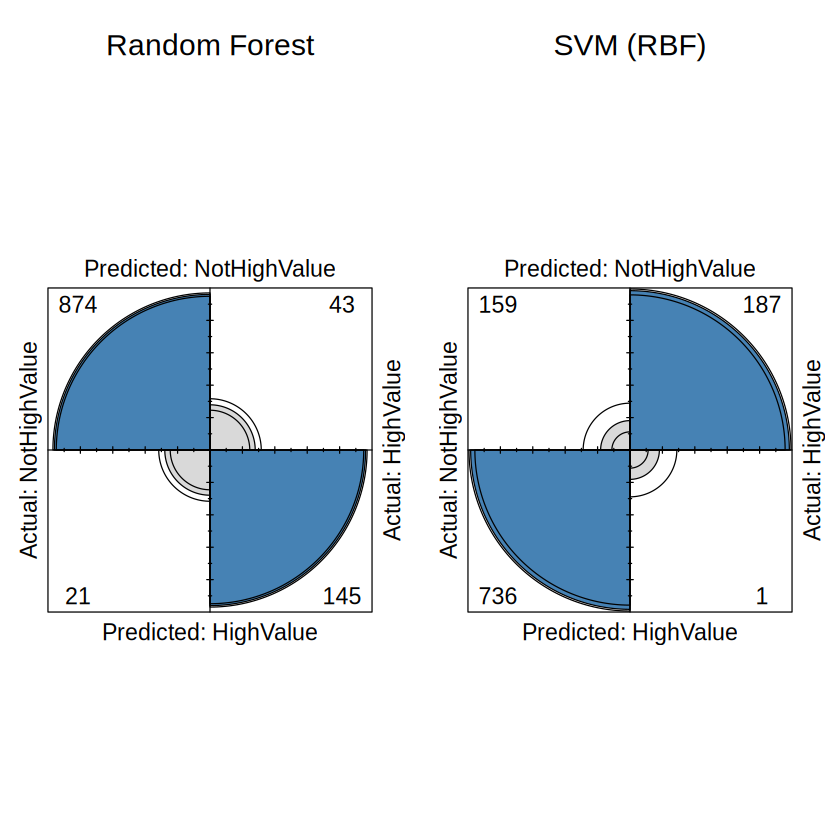

Best model by F1-Score: Random Forest 


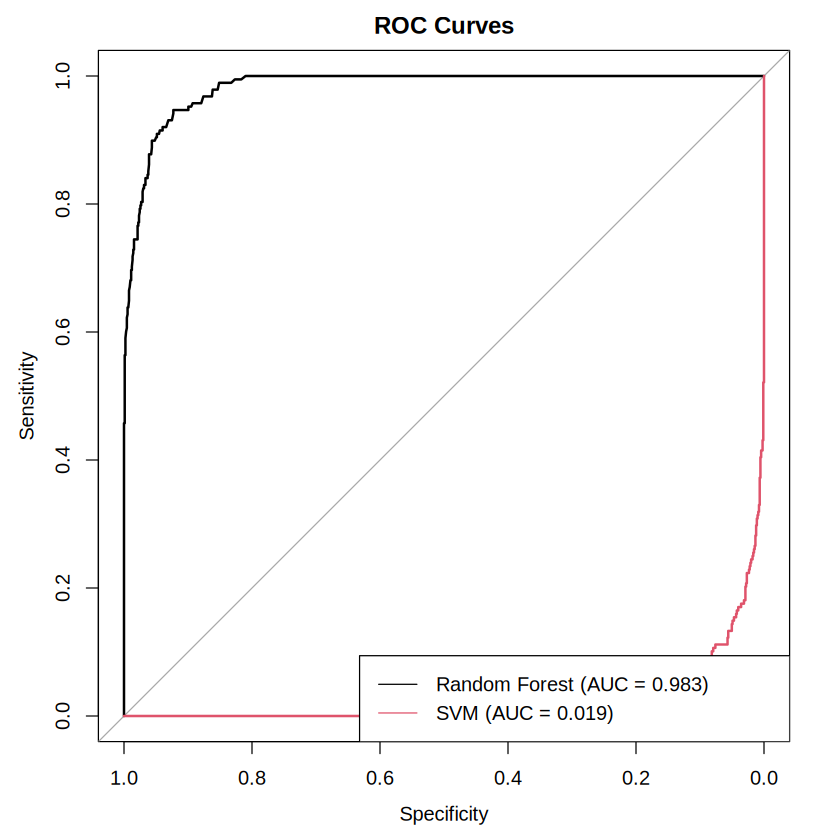

In [18]:
# Confusion matrices (rows = predicted class, columns = actual class)
cm_rf <- table(Predicted = factor(rf_pred, levels = levels(y_test)), Actual = y_test)
cm_svm <- table(Predicted = factor(svm_pred, levels = levels(y_test)), Actual = y_test)
print(cm_rf)
print(cm_svm)
par(mfrow = c(1, 2))
fourfoldplot(cm_rf, main = "Random Forest", color = c("grey85", "steelblue"))
fourfoldplot(cm_svm, main = "SVM (RBF)", color = c("grey85", "steelblue"))
par(mfrow = c(1, 1))

# ROC curves and AUC
roc_rf <- pROC::roc(y_test, rf_prob, levels = c("NotHighValue", "HighValue"), direction = "<", quiet = TRUE)
roc_svm <- pROC::roc(y_test, svm_prob, levels = c("NotHighValue", "HighValue"), direction = "<", quiet = TRUE)
plot(roc_rf, col = 1, main = "ROC Curves")
plot(roc_svm, col = 2, add = TRUE)
legend("bottomright", legend = c(sprintf("Random Forest (AUC = %.3f)", as.numeric(pROC::auc(roc_rf))),
                                  sprintf("SVM (AUC = %.3f)", as.numeric(pROC::auc(roc_svm)))), col = 1:2, lty = 1)
best <- results$Model[which.max(results$`F1-Score`)]
cat("Best model by F1-Score:", best, "\n")


## 15. Feature Importance Analysis

              Feature Importance PermutationImportance
1       TotalQuantity  374.97566           0.461988251
2          TenureDays  211.05986           0.369311487
3   PurchaseFrequency  161.30713           0.123949961
4    AvgQtyPerInvoice   56.24358           0.015966899
5      UniqueProducts   45.92331           0.012690213
6        AvgUnitPrice   33.26567           0.012078394
7 AvgTransactionValue   31.11145           0.015478744
8          CancelRate   17.89919           0.006341260
9                IsUK    1.51247           0.002266871


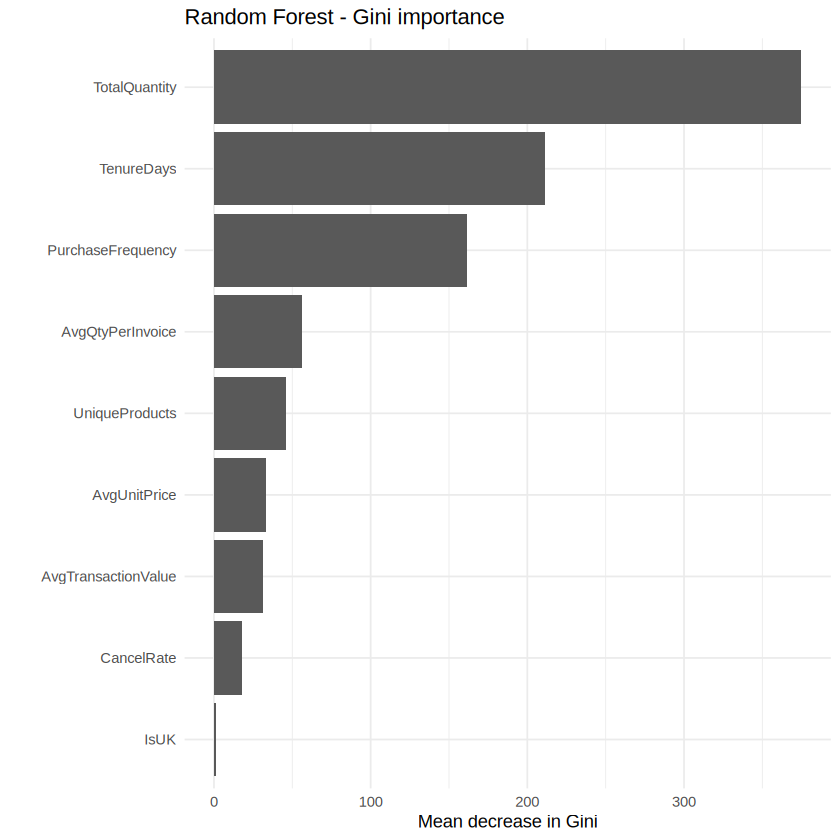

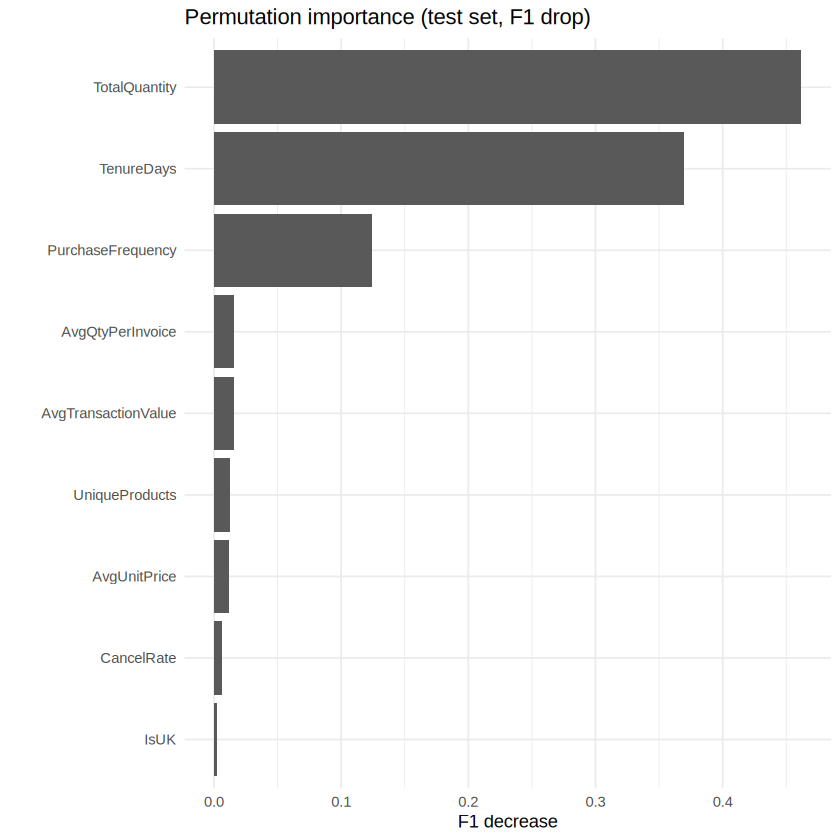

In [19]:
# Random Forest impurity-based importance
fi <- randomForest::importance(rf)
fi_df <- data.frame(Feature = rownames(fi), Importance = fi[, "MeanDecreaseGini"]) %>% arrange(Importance)
print(ggplot(fi_df, aes(reorder(Feature, Importance), Importance)) + geom_col() + coord_flip() +
        labs(title = "Random Forest - Gini importance", x = NULL, y = "Mean decrease in Gini") + theme_minimal())

# Permutation importance: average decrease in held-out F1 after permuting each feature.
f1_score_r <- function(truth, pred) {
  cm <- confusionMatrix(factor(pred, levels = levels(truth)), truth, positive = "HighValue")
  unname(cm$byClass["F1"])
}
set.seed(42)
base_f1 <- f1_score_r(y_test, predict(rf_fit, X_test))
perm_imp <- numeric(length(feat_cols)); names(perm_imp) <- feat_cols
for (feature in feat_cols) {
  drops <- replicate(5, {
    xperm <- X_test
    xperm[[feature]] <- sample(xperm[[feature]])
    base_f1 - f1_score_r(y_test, predict(rf_fit, xperm))
  })
  perm_imp[feature] <- mean(drops)
}
pi_df <- data.frame(Feature = names(perm_imp), PermutationImportance = as.numeric(perm_imp))
importance_df <- full_join(fi_df, pi_df, by = "Feature")
print(importance_df %>% arrange(desc(Importance)))
print(ggplot(pi_df, aes(reorder(Feature, PermutationImportance), PermutationImportance)) + geom_col() + coord_flip() +
        labs(title = "Permutation importance (test set, F1 drop)", x = NULL, y = "F1 decrease") + theme_minimal())


## 16. Interactive 3D Visualisation of Customer Clusters (Plotly)

In [20]:
plot_df <- data.frame(
  `Recency (scaled)` = X[, 1], `Frequency (scaled)` = X[, 2], `Monetary (scaled)` = X[, 3],
  Segment = cust$Segment, CustomerID = cust$CustomerID,
  `Monetary (GBP)` = round(cust$Monetary, 0), `Recency (days)` = cust$Recency,
  `Frequency (orders)` = cust$Frequency, check.names = FALSE
)
# For very large datasets, sample points to keep the interactive widget responsive.
set.seed(42)
plot_df_3d <- if (nrow(plot_df) > 5000) plot_df[sample(seq_len(nrow(plot_df)), 5000), ] else plot_df
plot_ly(plot_df_3d, x = ~`Recency (scaled)`, y = ~`Frequency (scaled)`, z = ~`Monetary (scaled)`,
        color = ~Segment, type = "scatter3d", mode = "markers",
        marker = list(size = 3, opacity = 0.75),
        text = ~paste("Customer:", CustomerID, "<br>Recency:", `Recency (days)`,
                      "<br>Orders:", `Frequency (orders)`, "<br>Monetary (GBP):", `Monetary (GBP)`),
        hoverinfo = "text") %>% layout(title = "3D RFM Customer Segments (K-Means)", height = 700)


Warning message:
“Specifying width/height in layout() is now deprecated.
Please specify in ggplotly() or plot_ly()”


HTML widgets cannot be represented in plain text (need html)

## 17. Segment-wise Targeted Marketing Recommendations

In [21]:
strategy_book <- list(
  "Champions" = c("Recently, frequently and heavily purchasing; top revenue contributors.",
                  "VIP / loyalty tier, early access to new products, exclusive offers, personal account managers, referral rewards. Avoid heavy discounting - they already buy."),
  "Loyal" = c("Regular buyers with good spend and fairly recent activity.",
              "Cross-sell and up-sell bundles, loyalty points, personalised recommendations, nudge towards the Champions tier with spend-based rewards."),
  "At-Risk" = c("Used to buy decently but have not purchased for a long time.",
                "Win-back email/SMS campaigns, 'we miss you' time-limited discounts, reminders based on past purchases, short feedback survey."),
  "New" = c("Recent customers with low frequency and spend.",
            "Welcome series, onboarding offers on a second purchase, product education, free-shipping threshold to raise basket size."),
  "Lost" = c("Low spend, low frequency and long inactive.",
             "Low-cost reactivation (one final deep-discount campaign); otherwise suppress from paid channels to save marketing budget.")
)
lookup_strategy <- function(name) {
  for (key in names(strategy_book)) if (startsWith(name, key)) return(strategy_book[[key]])
  c("-", "-")
}
rec <- profile %>% select(KMeans_Cluster, Customers, `% Customers`, `Revenue Share %`, Recency, Frequency, Monetary) %>%
  mutate(Segment = unname(seg_names[as.character(KMeans_Cluster)]))
strategies <- lapply(rec$Segment, lookup_strategy)
rec$Profile <- vapply(strategies, `[`, character(1), 1)
rec$`Recommended Marketing Strategy` <- vapply(strategies, `[`, character(1), 2)
rec <- rec %>% arrange(desc(Monetary)) %>% mutate(across(where(is.numeric), ~round(.x, 1)))
print(rec, width = Inf)


# A tibble: 4 × 10
  KMeans_Cluster Customers `% Customers` `Revenue Share %` Recency Frequency
  <fct>              <dbl>         <dbl>             <dbl>   <dbl>     <dbl>
1 0                    753          17.4              65.7    12.6      13.2
2 3                   1178          27.2              23.5    69.7       4  
3 1                    888          20.5               4.8    22.6       1.9
4 2                   1515          35                 6     193         1.3
  Monetary Segment                    
     <dbl> <chr>                      
1    7621  Champions (High-Value)     
2    1745  At-Risk / Hibernating      
3     472. Loyal / Potential Loyalists
4     346. Lost / Inactive            
  Profile                                                               
  <chr>                                                                 
1 Recently, frequently and heavily purchasing; top revenue contributors.
2 Used to buy decently but have not purchased for a long time.    

## 18. Interpretation of Results

* **Clustering:** The Elbow curve and Silhouette Score were used to choose *K*. K-Means and Ward hierarchical clustering produce broadly consistent groups (see the Adjusted Rand Index and cross-tab). PCA shows the clusters separated mainly along the monetary/frequency axis (PC1) and the recency axis (PC2).
* **Customer profiles:** A small group of *Champions* generates a disproportionately large share of revenue (see "Revenue Share %"), while the largest groups consist of low-frequency or inactive customers.
* **Prediction:** Both Random Forest and SVM can identify high-value customers from behavioural features **without** using RFM directly. Compare the metrics table: Recall is the most important metric for marketing (missing a high-value customer is costly), while Precision controls wasted campaign spend. ROC-AUC summarises ranking quality independent of the threshold.
* **Feature importance:** Features such as average transaction value, total quantity, product variety and purchase frequency are the strongest predictors, which confirms that basket size and breadth of purchase distinguish high-value customers.

## 19. Conclusion
The pipeline cleaned 541,909 raw transactions, engineered customer-level RFM and behavioural features, segmented customers with K-Means (validated by Elbow, Silhouette and hierarchical clustering), visualised them in 2D (PCA) and 3D (Plotly), profiled each segment and built Random Forest and SVM models that predict high-value membership with strong performance. The resulting segment-wise strategies (VIP retention, loyalty up-selling, win-back, onboarding, and cost-efficient handling of lost customers) can directly support data-driven marketing decisions.

**Limitations / future work:** the data covers one year of a single UK retailer; K-Means assumes spherical clusters; RFM was computed on the full period (a time-based train/future split would give a true churn/CLV forecast); other models (XGBoost, Gaussian Mixture, DBSCAN) could be explored.

## 20. References
* Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
* Scikit-learn, SciPy, Plotly documentation.